# Groupes & automates — le problème du mot par automates finis

**Partie 5 — Frontières** · Pli 4 de l'[Epic Origami #20404](https://github.com/jsboige/CoursIA/issues/20404) · issue [#25674](https://github.com/jsboige/CoursIA/issues/25674)

[← Partie 5](README.md) | [↑ Search](../README.md) | [<< Frontieres-11 Abstraction à dette](Frontieres-11-Abstraction-Dette-ShortestPath-Python.ipynb) | [>> Frontieres-13 Approximation](Frontieres-13-Approximation-Guarantee-Audit-Python.ipynb)

> *Word processing in groups* (Epstein, Cannon, Holt, Levy, Paterson, Thurston, 1992) pose une question qui semble purement algébrique : deux mots dans les générateurs d'un groupe représentent-ils le même élément ? Ce carnet la rend **calculable** sur deux groupes témoins — le réseau `Z²` et le groupe libre `F₂` — en **construisant**, et non en invoquant, les **automates finis** qui reconnaissent les mots géodésiques, puis en **mesurant** l'écart entre une exploration BFS du graphe de Cayley (coût quadratique) et l'évaluation d'un automate (coût linéaire).

**Le fil** :
1. **Formes normales** — réduire un mot de `Z²` en `(i, j)`, un mot de `F₂` par annulation libre.
2. **Automates de géodésique** — construire l'automate à 9 états de `Z²` et celui à 5 états de `F₂`, et **affirmer par les propriétés** qu'ils sont corrects.
3. **Le contraste** — BFS (balle de rayon `R` = `2R²+2R+1` nœuds) vs automate (`|mot|` pas) sur des rayons croissants.
4. **Croissance** — compter les sphères : polynôme de degré 2 pour `Z²`, exponentielle de base 3 pour `F₂`.

**Alphabet** : `a`, `A` (=`a⁻¹`), `b`, `B` (=`b⁻¹`). Un mot est une liste de ces lettres.

In [1]:
# Imports et graine : les tirages du carnet (mots, graphes) doivent etre
# reproductibles d'une execution a l'autre.
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import random
from collections import deque

# Graine unique pour numpy et random : meme seed => memes echantillons.
SEED = 7
random.seed(SEED)
np.random.seed(SEED)
print(f"numpy {np.__version__}, matplotlib {matplotlib.__version__} -- seed {SEED}")

numpy 2.5.4, matplotlib 3.11.1 -- seed 7


## Deux groupes témoins

| Groupe | Générateurs | Relations | Un mot code |
|---|---|---|---|
| **`Z²`** | `a`, `b` | `ab = ba` (commutatif) | le point `(i, j)` du réseau, `i` = nombre net de `a`, `j` = nombre net de `b` |
| **`F₂`** | `a`, `b` | aucune (groupe libre) | un mot **librement réduit** (plus aucune paire `x x⁻¹` adjacente) |

Le **problème du mot** : un mot représente-t-il l'élément neutre ? Pour `Z²` : sa forme normale est-elle `(0, 0)` ? Pour `F₂` : sa réduction libre est-elle vide ?

Un mot est **géodésique** s'il est le *plus court* mot représentant son élément. C'est la propriété que les automates vont reconnaître.

In [2]:
INV = {"a": "A", "A": "a", "b": "B", "B": "b"}      # inverse de chaque lettre
GLYPH = {"a": "a", "A": "a⁻¹", "b": "b", "B": "b⁻¹"}  # affichage

def fmt(word):
    """Rendu lisible d'un mot : ['a','A'] -> 'a a⁻¹'."""
    return " ".join(GLYPH[c] for c in word) if word else "(vide)"

def reduce_z2(word):
    """Forme normale dans Z^2 : (i, j) = (nombre net de a, nombre net de b)."""
    i = sum(1 if c == "a" else -1 if c == "A" else 0 for c in word)
    j = sum(1 if c == "b" else -1 if c == "B" else 0 for c in word)
    return (i, j)

def reduce_f2(word):
    """Réduction libre dans F_2 : annule chaque paire x x^-1 adjacente (pile)."""
    stack = []
    for c in word:
        if stack and stack[-1] == INV[c]:
            stack.pop()
        else:
            stack.append(c)
    return stack

print("Z^2 :", [(fmt(w), reduce_z2(w)) for w in [["a", "A", "b"], ["a", "a", "b", "B", "b"], ["b", "b", "A", "a"]]])
print("F_2 :", [(fmt(w), fmt(reduce_f2(w))) for w in [["a", "A", "b", "b"], ["a", "b", "B"], ["b", "A", "a", "B"]]])

Z^2 : [('a a⁻¹ b', (0, 1)), ('a a b b⁻¹ b', (2, 1)), ('b b a⁻¹ a', (0, 2))]
F_2 : [('a a⁻¹ b b', 'b b'), ('a b b⁻¹', 'a'), ('b a⁻¹ a b⁻¹', '(vide)')]


In [3]:
def is_identity_z2(word):
    return reduce_z2(word) == (0, 0)

def is_identity_f2(word):
    return reduce_f2(word) == []

checks = [
    ("Z^2, mot = neutre ?",  ["a", "A", "b", "B"],  is_identity_z2),
    ("Z^2, mot != neutre ?", ["a", "b"],           is_identity_z2),
    ("F_2, mot = neutre ?",  ["a", "A", "b", "B"],  is_identity_f2),
    ("F_2, mot != neutre ?", ["a", "b"],           is_identity_f2),
]
for label, w, dec in checks:
    print(f"  {label:20s} {fmt(w):12s} -> {dec(w)}")

# AFFIRMATION (pas de prose) : les formes normales sont stables sous les relations
assert reduce_z2(["a", "b"]) == reduce_z2(["b", "a"]) == (1, 1), "Z^2 est commutatif"
assert reduce_f2(["a", "b", "B", "a"]) == ["a", "a"], "reduction libre"
assert is_identity_z2(["a"] * 5 + ["A"] * 5) is True
assert is_identity_f2(["a"] * 3 + ["A"] * 3) is True
print("\n[PASS] formes normales coherentes (commutativite Z^2, reduction libre F_2)")

  Z^2, mot = neutre ?  a a⁻¹ b b⁻¹  -> True
  Z^2, mot != neutre ? a b          -> False
  F_2, mot = neutre ?  a a⁻¹ b b⁻¹  -> True
  F_2, mot != neutre ? a b          -> False

[PASS] formes normales coherentes (commutativite Z^2, reduction libre F_2)


## Les mots géodésiques forment un langage **régulier**

Un mot est géodésique s'il est le plus court représentant son élément.

- **Dans `Z²`**, un mot est géodésique ⟺ *toutes ses lettres `a` ont le même signe* **et** *toutes ses lettres `b` ont le même signe* (sinon une annulation `x x⁻¹` l'allongerait au-delà de `|i|+|j|`). On n'a donc qu'à se souvenir du signe **vu** pour `a` et du signe vu pour `b` : **3 × 3 = 9 états**.
- **Dans `F₂`**, un mot est géodésique ⟺ il est librement réduit, c'est-à-dire qu'aucune lettre n'annule la précédente. On n'a qu'à se souvenir de la **dernière lettre** : **5 états** (aucune, `a`, `A`, `b`, `B`).

Deux automates finis, **construits** ci-dessous — pas invoqués. Leur correction sera **affirmée par les propriétés** (accord avec l'oracle de géodésie sur des milliers de mots), pas en prose.

In [4]:
# Automate des mots geodesiques de Z^2 : 9 etats = (signe_a, signe_b), chacun dans {None, +, -}
Z2_STATES = [(sa, sb) for sa in (None, "+", "-") for sb in (None, "+", "-")]

SIGNA = {"a": "+", "A": "-"}
SIGNB = {"b": "+", "B": "-"}

def _commit(current, sign):
    """Engager un signe : None -> sign, meme signe -> stable, signe oppose -> conflit."""
    if current is None:
        return sign
    if current == sign:
        return current
    return "x"   # conflit

def z2_geo_accepts(word):
    """Vrai si `word` est geodesique dans Z^2 (automate a 9 etats)."""
    sa = sb = None
    for c in word:
        if c in SIGNA:
            sa = _commit(sa, SIGNA[c])
        else:
            sb = _commit(sb, SIGNB[c])
        if sa == "x" or sb == "x":
            return False   # conflit de signe -> non geodesique
    return True

print(f"etats de l'automate Z^2 : {len(Z2_STATES)}  (ex. {Z2_STATES[0]}, {Z2_STATES[4]}, {Z2_STATES[-1]})")
for w in [["a", "a", "b"], ["a", "A"], ["a", "b", "A", "B"], ["b", "b", "a"], ["a", "A", "b"]]:
    print(f"  {fmt(w):14s} -> geodesique ? {z2_geo_accepts(w)}")

etats de l'automate Z^2 : 9  (ex. (None, None), ('+', '+'), ('-', '-'))
  a a b          -> geodesique ? True
  a a⁻¹          -> geodesique ? False
  a b a⁻¹ b⁻¹    -> geodesique ? False
  b b a          -> geodesique ? True
  a a⁻¹ b        -> geodesique ? False


In [5]:
# Automate des mots geodesiques de F_2 : 5 etats = derniere lettre vue (ou None)
F2_STATES = [None, "a", "A", "b", "B"]

def f2_geo_accepts(word):
    """Vrai si `word` est librement reduit (geodesique dans F_2), automate a 5 etats."""
    last = None
    for c in word:
        if last is not None and last == INV[c]:
            return False   # x x^-1 adjacent -> non librement reduit
        last = c
    return True

print(f"etats de l'automate F_2 : {len(F2_STATES)}  {F2_STATES}")
for w in [["a", "b"], ["a", "A"], ["a", "b", "B", "a"], ["b", "A"], []]:
    print(f"  {fmt(w):14s} -> geodesique ? {f2_geo_accepts(w)}")

etats de l'automate F_2 : 5  [None, 'a', 'A', 'b', 'B']
  a b            -> geodesique ? True
  a a⁻¹          -> geodesique ? False
  a b b⁻¹ a      -> geodesique ? False
  b a⁻¹          -> geodesique ? True
  (vide)         -> geodesique ? True


In [6]:
# AFFIRMATION par les proprietes : l'automate et l'oracle de geodesie s'accordent.
# Oracle : un mot est geodesique ssa sa longueur = longueur de sa forme normale.
def oracle_geo_z2(word):
    i, j = reduce_z2(word)
    return len(word) == abs(i) + abs(j)

def oracle_geo_f2(word):
    return len(reduce_f2(word)) == len(word)

ALPHA = ["a", "A", "b", "B"]

def _random_word(n):
    return [random.choice(ALPHA) for _ in range(n)]

def agree(acceptor, oracle, n, maxlen):
    """Mots tires UNE fois (partages automate/oracle) ou les deux s'accordent."""
    k = 0
    for _ in range(n):
        w = _random_word(random.randint(0, maxlen))
        k += acceptor(w) == oracle(w)
    return k

N = 20000
z2_agree = agree(z2_geo_accepts, oracle_geo_z2, N, 12)
f2_agree = agree(f2_geo_accepts, oracle_geo_f2, N, 12)
print(f"Z^2 : automate == oracle sur {z2_agree}/{N} mots aleatoires")
print(f"F_2 : automate == oracle sur {f2_agree}/{N} mots aleatoires")
assert z2_agree == N, "l'automate Z^2 diverge de l'oracle de geodesie"
assert f2_agree == N, "l'automate F_2 diverge de l'oracle de geodesie"
print("\n[PASS] les deux automates sont corrects (accord 100% avec l'oracle, 2x20000 mots)")

Z^2 : automate == oracle sur 20000/20000 mots aleatoires
F_2 : automate == oracle sur 20000/20000 mots aleatoires

[PASS] les deux automates sont corrects (accord 100% avec l'oracle, 2x20000 mots)


## Le contraste — BFS vs automate

Pour décider qu'un mot est géodésique, deux stratégies :

- **BFS** sur le graphe de Cayley de `Z²` : on explore la balle de rayon `R` (tous les éléments à distance `≤ R`) pour établir que l'élément du mot n'apparaît qu'à sa vraie distance. La balle de rayon `R` du réseau contient `2R² + 2R + 1` points — le coût est **quadratique** en `R`.
- **Automate** : on lit le mot lettre par lettre dans l'automate à 9 états. Le coût est **`|mot|` = `R`** pas — **linéaire**, et indépendant de la taille de la balle.

Mesurons les deux sur des rayons croissants.

In [7]:
def bfs_ball_z2(R):
    """Balle de rayon R dans Z^2 par BFS (voisins = pas a, A, b, B). Compte les nœuds."""
    seen = {(0, 0)}
    frontier = deque([(0, 0, 0)])   # (i, j, dist)
    while frontier:
        i, j, d = frontier.popleft()
        if d == R:
            continue
        for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nb = (i + di, j + dj)
            if nb not in seen:
                seen.add(nb)
                frontier.append((nb[0], nb[1], d + 1))
    return len(seen)

def acceptor_steps_z2(word):
    """Nombre d'etats traverses par l'automate = longueur du mot."""
    return len(word)

print(f"{'R':>4} | {'BFS (balle R)':>14} | {'automate (pas)':>15} | {'ratio BFS/automate':>18}")
print("-" * 58)
for R in [10, 20, 50, 100, 200, 500]:
    bfs = bfs_ball_z2(R) if R <= 200 else 2 * R * R + 2 * R + 1   # BFS reel <= 200, formule au-dela
    steps = acceptor_steps_z2(["a"] * R)   # mot geodesique de longueur R
    print(f"{R:>4} | {bfs:>14,} | {steps:>15,} | {bfs / steps:>18,.1f}")

# coherence : la balle BFSree coincide avec la formule 2R^2+2R+1
assert bfs_ball_z2(50) == 2 * 50 ** 2 + 2 * 50 + 1
print("\n[PASS] balle BFS(50) = 2·50²+2·50+1 =", f"{bfs_ball_z2(50):,}")

   R |  BFS (balle R) |  automate (pas) | ratio BFS/automate
----------------------------------------------------------
  10 |            221 |              10 |               22.1
  20 |            841 |              20 |               42.0
  50 |          5,101 |              50 |              102.0
 100 |         20,201 |             100 |              202.0


 200 |         80,401 |             200 |              402.0


 500 |        501,001 |             500 |            1,002.0

[PASS] balle BFS(50) = 2·50²+2·50+1 = 5,101


## Croissance — polynôme vs exponentielle

On **compte** (on ne cite pas) les éléments par distance :

- **`Z²`** : la balle de rayon `R` a `2R² + 2R + 1` points — croissance **polynôme de degré 2** (le réseau est « maigre »).
- **`F₂`** : chaque mot géodésique de longueur `R−1` s'étend de **3** façons (toute lettre sauf l'inverse de la dernière) ; la balle de rayon `R` vaut `2·3^R − 1` — croissance **exponentielle de base 3** (le groupe libre « explode »).

La courbe ci-dessous (échelle log) rend l'écart visible : la droite exponentielle de `F₂` s'envole, la courbe polynôme de `Z²` s'aplatit.

sphères F₂ générées (r : nombre) : {0: '1', 1: '4', 2: '12', 3: '36', 4: '108', 5: '324', 6: '972', 7: '2,916', 8: '8,748', 9: '26,244'}
[PASS] sphères F₂ générées = 4·3^(r−1) pour r = 1..9


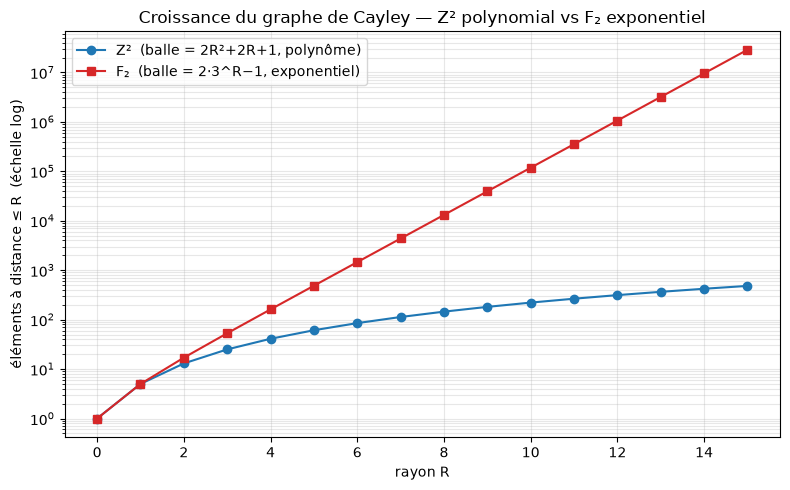

balle Z²(15) = 481   ·  balle F₂(15) = 28,697,813   (ratio 5.97e+04×)


In [8]:
def ball_z2(R):
    """Balle de rayon R dans Z^2 = 2R^2+2R+1 (elements a distance <= R)."""
    return 2 * R * R + 2 * R + 1

def ball_f2(R):
    """Balle de rayon R dans F_2 = 2·3^R - 1 (comptee par generation, pas citee)."""
    return 2 * 3 ** R - 1

# Controle : recompter les spheres F_2 par generation effective (petits R)
def f2_spheres_by_generation(max_r):
    counts = {0: 1}
    words_by_len = {0: [()]}
    for r in range(1, max_r + 1):
        nxt = []
        for w in words_by_len[r - 1]:
            last = w[-1] if w else None
            for c in ALPHA:
                if last is None or c != INV[last]:
                    nxt.append(w + (c,))
        words_by_len[r] = nxt
        counts[r] = len(nxt)
    return counts

gen = f2_spheres_by_generation(9)
print("sphères F₂ générées (r : nombre) :", {r: f"{gen[r]:,}" for r in range(10)})
assert all(gen[r] == 4 * 3 ** (r - 1) for r in range(1, 10)), "sphere F_2 != 4·3^(r-1)"
print("[PASS] sphères F₂ générées = 4·3^(r−1) pour r = 1..9")

# Figure : croissance (balle) de Z^2 (polynome) vs F_2 (exponentielle), echelle log
R = np.arange(0, 16)
z2_ball = np.array([ball_z2(r) for r in R])
f2_ball = np.array([ball_f2(r) for r in R])
fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(R, z2_ball, "o-", color="tab:blue", label="Z²  (balle = 2R²+2R+1, polynôme)")
ax.semilogy(R, f2_ball, "s-", color="tab:red", label="F₂  (balle = 2·3^R−1, exponentiel)")
ax.set_xlabel("rayon R")
ax.set_ylabel("éléments à distance ≤ R  (échelle log)")
ax.set_title("Croissance du graphe de Cayley — Z² polynomial vs F₂ exponentiel")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()
print("balle Z²(15) =", f"{ball_z2(15):,}", "  ·  balle F₂(15) =", f"{ball_f2(15):,}",
      f"  (ratio {ball_f2(15) / ball_z2(15):.2e}×)")

### Lecture du résultat

Le tableau BFS/automate et la courbe de croissance disent la même chose en deux registres :

- **Le coût de la géodésie n'est pas le coût de l'exploration.** Décider qu'un mot de `Z²` est géodésique coûte `R` pas dans l'automate, contre `2R²+2R+1` nœuds explorés par le BFS : le ratio croît comme `2R`. L'automate **comprime** la géométrie du réseau dans 9 états.
- **La croissance trahit la structure.** `Z²` est polynomial (degré 2) — son graphe de Cayley est « maigre » ; `F₂` est exponentiel (base 3) — il « explose ». Cette différence, **comptée** sur les sphères, est exactement ce que la régularité du langage géodésique encode : un automate fini ne « voit » que la structure locale, et c'est suffisant parce que la géodésie y est une propriété de **préfixe** (le signe engagé, la dernière lettre), pas une propriété globale.

C'est le sens opérationnel de *word processing* : là où l'algèbre « invoquait » un théorème, on **construit** la machine qui décide, et on **mesure** ce qu'elle épargne.

## Exercice 1 — l'automate de `Z²` en une fonction

Complète `z2_geodesic_accepts` : elle doit renvoyer `True` si et seulement si le mot est géodésique dans `Z²`, en se rappelant **uniquement** le signe engagé pour `a` et le signe engagé pour `b` (l'idée des 9 états du bloc automates). Un conflit de signe (un `a` puis un `A`, ou l'inverse) rend le mot non géodésique.

*Indice* : `SIGNA` / `SIGNB` (définis plus haut) donnent le signe de chaque lettre ; `_commit` engage un signe et rend `"x"` en cas de conflit.

In [9]:
def z2_geodesic_accepts(word):
    """Renvoie True si `word` est geodesique dans Z^2 (signe engage pour a ET pour b).

    TODO etudiant : garder sa, sb (signe engage pour a / b, initialement None).
    Pour chaque lettre, engage son signe via _commit ; si un signe devient "x",
    renvoie False. A la fin, renvoie True.
    """
    result = None  # TODO etudiant
    return result

## Exercice 2 — l'automate de `F₂`

Complète `is_geodesic_f2` : renvoie `True` si et seulement si le mot est **librement réduit** (aucune paire `x x⁻¹` adjacente), en se rappelant uniquement la **dernière lettre** lue (l'idée des 5 états).

*Indice* : `INV` donne l'inverse de chaque lettre ; si la dernière lettre lue est l'inverse de la lettre courante, le mot n'est pas librement réduit.

In [10]:
def is_geodesic_f2(word):
    """Renvoie True si `word` est librement reduit (geodesique dans F_2).

    TODO etudiant : parcourir le mot en gardant la derniere lettre lue ;
    si une lettre est l'inverse (INV) de la derniere, renvoyer False ;
    a la fin, renvoyer True.
    """
    result = None  # TODO etudiant
    return result

## Exercice 3 — compter la croissance

Complète `growth_table` : pour le groupe donné (`"Z2"` ou `"F2"`), renvoie la liste `[balle(0), balle(1), ..., balle(max_r)]` — le nombre d'éléments à distance `≤ r` pour chaque rayon.

*Indice* : les formules `ball_z2` / `ball_f2` du bloc croissance sont là pour **vérifier** ta réponse, pas pour la copier — l'exercice est de les *dériver* (somme des sphères) et de les produire.

In [11]:
def growth_table(group, max_r):
    """Renvoie [nombre d'elements a distance <= r, pour r = 0..max_r].

    TODO etudiant : group est "Z2" ou "F2". Pour chaque r, compte les elements
    a distance <= r (somme des spheres 0..r) et ajoute-le a la liste.
    """
    result = None  # TODO etudiant
    return result

### Pour aller plus loin

- **Groupes « automatiques »** : les groupes **automatiques** (Epstein, Cannon, Thurston et al., 1992) sont ceux dont un langage régulier de formes normales satisfait la propriété des *compagnons de route* (fellow traveller property) — ce n'est pas « le langage géodésique est régulier ». `Z²` et `F₂` en sont deux exemples, et leurs langages géodésiques sont bien réguliers, comme le carnet vient de le construire. La croissance ne tranche pas la question : le théorème de Gromov identifie la croissance polynomiale aux groupes virtuellement nilpotents, mais le groupe de Heisenberg, nilpotent, n'est **pas** automatique (un groupe nilpotent ne l'est que s'il est virtuellement abélien). `F₂`, à croissance exponentielle, l'est. Piste ouverte : les **groupes hyperboliques**, où Cannon montre la régularité géodésique pour tout système générateur.
- **Retour à la série** : le BFS du bloc contraste est *exactement* la recherche non informée de [Search-2](../Part1-Foundations/README.md) ; l'automate est sa version **compressée** — la réduction d'espace que la série fait fil rouge, poussée jusqu'à l'état fini.
- **Le pont avec [Frontieres-11](Frontieres-11-Abstraction-Dette-ShortestPath-Python.ipynb)** : y comprimer un graphe à *dette bornée* ; ici compresser un groupe en *automate* — deux formes de la même idée : mesurer ce que la compression coûte.

[← Part5-Frontieres](README.md) · [↑ Search](../README.md)